<a href="https://colab.research.google.com/github/janisharanjani-byte/GenAi_playground/blob/main/Customer_Churn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [8]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (classification_report, confusion_matrix,
                             roc_auc_score, ConfusionMatrixDisplay)
from sklearn.utils.class_weight import compute_class_weight

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

CSV_PATH = "WA_Fn-UseC_-Telco-Customer-Churn.csv"
FEATURES = ["tenure", "MonthlyCharges", "TotalCharges", "SeniorCitizen"]


In [2]:
# ------------------------------------------------------------------ 1. DATA
def load_data(path=CSV_PATH):
    if os.path.exists(path):
        df = pd.read_csv(path)
        # TotalCharges contains blank strings for brand-new customers
        df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
        df["TotalCharges"] = df["TotalCharges"].fillna(0.0)
        df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})
        return df[FEATURES + ["Churn"]]

    print("CSV not found -> generating synthetic data.")
    n = 5000
    tenure = np.random.randint(0, 73, n)
    monthly = np.round(np.random.uniform(18, 120, n), 2)
    senior = np.random.binomial(1, 0.16, n)
    total = np.round(tenure * monthly + np.random.normal(0, 30, n), 2).clip(0)
    logit = (-1.0 - 0.045 * tenure + 0.02 * (monthly - 65) + 0.6 * senior)
    churn = (np.random.rand(n) < 1 / (1 + np.exp(-logit))).astype(int)
    return pd.DataFrame({"tenure": tenure, "MonthlyCharges": monthly,
                         "TotalCharges": total, "SeniorCitizen": senior,
                         "Churn": churn})


df = load_data()
print("Shape:", df.shape)
print("Churn rate: {:.1%}".format(df["Churn"].mean()))

X = df[FEATURES].values.astype("float32")
y = df["Churn"].values.astype("float32")

CSV not found -> generating synthetic data.
Shape: (5000, 5)
Churn rate: 11.7%


In [3]:
# --------------------------------------------------------- 2. PREPROCESSING
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)

scaler = StandardScaler()                    # fit on train only (no leakage)
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Churn is imbalanced (~26 %), so weight the classes
cw = compute_class_weight("balanced", classes=np.array([0, 1]), y=y_train)
class_weight = {0: cw[0], 1: cw[1]}
print("Class weights:", class_weight)

Class weights: {0: np.float64(0.5660911406736484), 1: np.float64(4.282655246252677)}


In [4]:
# ------------------------------------------------------------- 3. THE MODEL
model = keras.Sequential([
    layers.Input(shape=(X_train.shape[1],)),
    layers.Dense(16, activation="relu"),
    layers.BatchNormalization(),
    layers.Dropout(0.3),
    layers.Dense(8, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(1, activation="sigmoid"),   # probability of churn
], name="churn_ann")

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=["accuracy",
             keras.metrics.Precision(name="precision"),
             keras.metrics.Recall(name="recall"),
             keras.metrics.AUC(name="auc")],
)
model.summary()

Model: "churn_ann"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 16)             │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 289 (1.13 KB)

 Trainable params: 257 (1.00 KB)

 Non-trainable params: 32 (128.00 B)

In [5]:
# -------------------------------------------------------------- 4. TRAINING
callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=10,
                                  restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5,
                                      patience=4, min_lr=1e-5),
]

history = model.fit(
    X_train, y_train,
    validation_split=0.2,
    epochs=100,
    batch_size=32,
    class_weight=class_weight,
    callbacks=callbacks,
    verbose=2,
)

Epoch 1/100
100/100 - 4s - 37ms/step - accuracy: 0.4712 - auc: 0.6349 - loss: 0.7264 - precision: 0.1491 - recall: 0.7240 - val_accuracy: 0.6175 - val_auc: 0.7484 - val_loss: 0.6757 - val_precision: 0.1859 - val_recall: 0.7952 - learning_rate: 0.0010
Epoch 2/100
100/100 - 0s - 4ms/step - accuracy: 0.5756 - auc: 0.6629 - loss: 0.6792 - precision: 0.1727 - recall: 0.6693 - val_accuracy: 0.6475 - val_auc: 0.7523 - val_loss: 0.6336 - val_precision: 0.1994 - val_recall: 0.7952 - learning_rate: 0.0010
Epoch 3/100
100/100 - 0s - 4ms/step - accuracy: 0.5947 - auc: 0.6888 - loss: 0.6620 - precision: 0.1836 - recall: 0.6901 - val_accuracy: 0.6538 - val_auc: 0.7585 - val_loss: 0.6150 - val_precision: 0.1969 - val_recall: 0.7590 - learning_rate: 0.0010
Epoch 4/100
100/100 - 0s - 5ms/step - accuracy: 0.6134 - auc: 0.6987 - loss: 0.6459 - precision: 0.1916 - recall: 0.6901 - val_accuracy: 0.6562 - val_auc: 0.7646 - val_loss: 0.5953 - val_precision: 0.2000 - val_recall: 0.7711 - learning_rate: 0.0010

32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step

Test ROC-AUC: 0.7404

Classification report:
               precision    recall  f1-score   support

        Stay       0.94      0.67      0.79       883
       Churn       0.22      0.70      0.34       117

    accuracy                           0.68      1000
   macro avg       0.58      0.69      0.56      1000
weighted avg       0.86      0.68      0.73      1000

Saved churn_ann_results.png


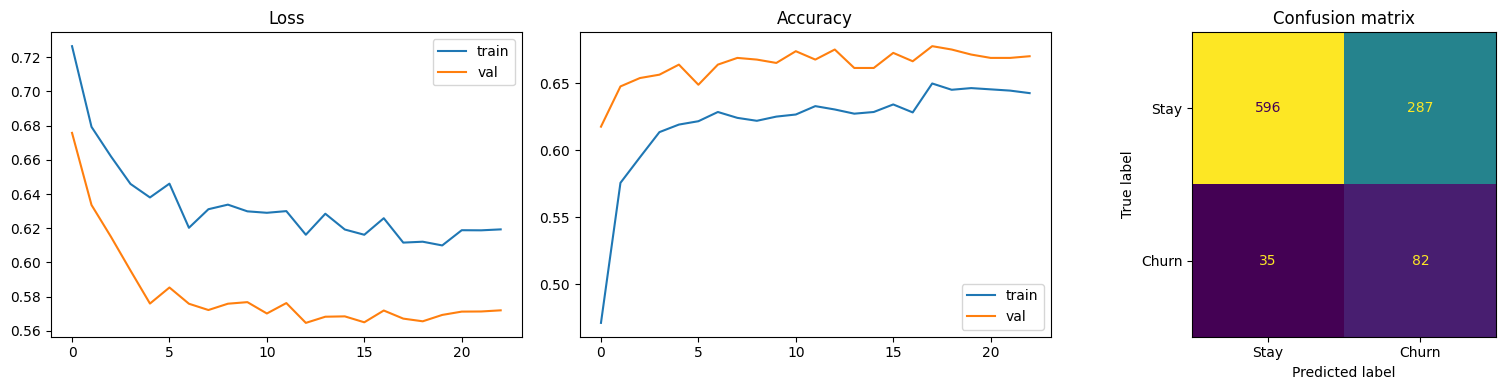

In [6]:
# ------------------------------------------------------------ 5. EVALUATION
y_prob = model.predict(X_test).ravel()
y_pred = (y_prob >= 0.5).astype(int)

print("\nTest ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))
print("\nClassification report:\n",
      classification_report(y_test, y_pred, target_names=["Stay", "Churn"]))

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].plot(history.history["loss"], label="train")
ax[0].plot(history.history["val_loss"], label="val")
ax[0].set_title("Loss"); ax[0].legend()
ax[1].plot(history.history["accuracy"], label="train")
ax[1].plot(history.history["val_accuracy"], label="val")
ax[1].set_title("Accuracy"); ax[1].legend()
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred),
                       display_labels=["Stay", "Churn"]).plot(ax=ax[2],
                                                              colorbar=False)
ax[2].set_title("Confusion matrix")
plt.tight_layout()
plt.savefig("churn_ann_results.png", dpi=150)
print("Saved churn_ann_results.png")


In [7]:
# --------------------------------------------------- 6. SAVE & PREDICT NEW
model.save("churn_ann.keras")
import joblib
joblib.dump(scaler, "scaler.pkl")


def predict_churn(tenure, monthly_charges, total_charges, senior_citizen,
                  threshold=0.5):
    """Return (churn probability, label) for a single customer."""
    x = scaler.transform([[tenure, monthly_charges, total_charges,
                           senior_citizen]])
    p = float(model.predict(x, verbose=0)[0][0])
    return p, ("Likely to CHURN" if p >= threshold else "Likely to STAY")


p, label = predict_churn(tenure=3, monthly_charges=95.0,
                         total_charges=285.0, senior_citizen=1)
print(f"\nExample customer -> churn probability = {p:.2%} ({label})")




Example customer -> churn probability = 75.31% (Likely to CHURN)
